## Imported libraries

In [1]:
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

import socket
import struct

## Configuration parameters

In [9]:
WIDTH = HEIGHT = 1024              # Size to which the image will be resized
WORD = 16                         # Length in bytes of the word used by DDR3

WRITE, READ = 0x01, 0x02          # System operation codes
CHUNK = 1024                      # Size in bytes of the sub-image sent in the UDP packet payload
IMAGE_DIR = "images"              

FPGA_IP = "192.168.1.128"
FPGA_PORT = 5678
LOCAL_PORT = 1234

METADATA = struct.Struct("!BIH")  # Structure of the metadata sent in the packet
BASE_ADDRESS = 0x1000             # Base address used by DDR3 memory
LENGTH = int(CHUNK/WORD)          # Number of words contained in the packet

## Functions

### Prepare the reference image

In [10]:
def prepare_img(filename:str, size:tuple):
  img_path = Path(f"images/{filename}") 
  with Image.open(img_path) as image:
    img_gray = image.convert("L").resize(size, Image.Resampling.BILINEAR)

  return img_gray

### Send a WRITE request to FPGA

In [11]:
def send_to_fpga(sock:socket, payload:bytearray, address:bytes, length:bytes):
  metadata = METADATA.pack(WRITE, address, length)
  sock.send(metadata + payload)

### Send a READ request to FPGA

In [12]:
def receive_from_fpga(sock:socket, address:bytes, length:bytes):
  metadata = METADATA.pack(READ, address, length)
  sock.send(metadata)
  
  try:
    payload = bytes(sock.recv(65535))
    return payload
      
  except socket.timeout:
    raise ValueError(f"READ timed out at address {address:#010x}.") from None

### Rebuild the image from the readback

In [13]:
def payload_to_image(payload:bytearray, size:tuple):
  return Image.frombytes("L", size, payload)

### Display the host image and FPGA readback

In [14]:
def display_images(img_host: Image, img_fpga:Image):
  fig, axes = plt.subplots(1, 2, figsize=(8, 4))

  for ax, image, title in zip(axes, [img_host, img_fpga], ["Host", "FPGA readback"]):
      ax.imshow(image, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
      ax.set_title(title)
      ax.axis("off")

  plt.tight_layout()
  plt.show()

## Writing and reading in DDR3

Does the sent payload match the received payload? True


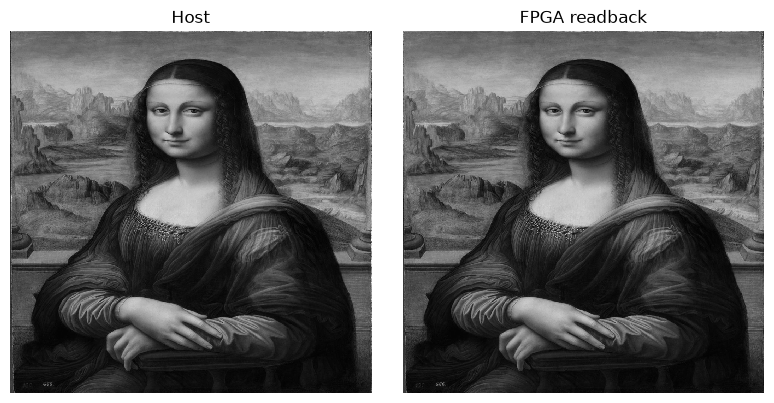

In [16]:
def ddr3_write_read(img_host:Image):
  payload_host = img_host.tobytes()
  payload_fpga = bytearray()

  try:
    with socket.socket(socket.AF_INET, socket.SOCK_DGRAM) as sock:
      sock.settimeout(5)
      sock.connect((FPGA_IP, FPGA_PORT))

      for offset in range(0, WIDTH * HEIGHT, CHUNK):
        block = payload_host[offset:offset+CHUNK]
        send_to_fpga(sock, block, BASE_ADDRESS + offset, LENGTH)

      for offset in range(0, WIDTH * HEIGHT, CHUNK):
        block = receive_from_fpga(sock, BASE_ADDRESS + offset, LENGTH)
        payload_fpga.extend(block)

      fpga_img = payload_to_image(payload_fpga, (WIDTH, HEIGHT))
      print(f"Does the sent payload match the received payload? {payload_fpga == payload_host}")
      return fpga_img
      

  except (OSError, ValueError, OverflowError) as error:
    print(f"Error: {error}\n")

if __name__ == "__main__":
  img_host = prepare_img("Gioconda.jpg", (WIDTH, HEIGHT))
  img_fpga = ddr3_write_read(img_host)

  display_images(img_host, img_fpga)